In [1]:
import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')
from analysis import collection, analysis, emg, plot, model
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import patches, lines
from pathlib import Path
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from joblib import dump, load
from analysis.offsets import offsets

mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({'axes.labelsize': 16})
mpl.rcParams.update({'figure.figsize': (16*0.8,9*0.8)})
mpl.rcParams.update({'axes.facecolor': "white"})
mpl.rcParams.update({'lines.marker': "+"})
mpl.rcParams.update({'lines.linestyle': ""})
mpl.rcParams.update({"axes.spines.left":   True})
mpl.rcParams.update({"axes.spines.bottom": True})
mpl.rcParams.update({"axes.spines.top":    False})
mpl.rcParams.update({"axes.spines.right":  False})

image_path = Path("/Users/spencer/phd/phd/images/methods/")

%matplotlib inline

In [2]:
if sys.platform == "linux":
    ROOT_RAWDATA_PATH = Path("/home/spencer/motor-control/data/rawdata/")
    ROOT_METADATA_PATH = Path("/home/spencer/motor-control/data/metadata/")  
else:   
    ROOT_RAWDATA_PATH = Path("/Users/spencer/motor-control/data/rawdata/")
    ROOT_METADATA_PATH = Path("/Users/spencer/motor-control/data/metadata/")

In [5]:
# collection_name = "emg_olympics"
# task_name = "center_hold"
# c = collection.Collection(collection_name)
# subjects = c.alphabetically_sorted_subjects()

In [6]:
# with open('olympics_subjects.pkl', 'wb') as handle:
#     pickle.dump(subjects, handle)

In [2]:
task_name = "center_hold"
subjects = analysis.load_subjects()
print(len(subjects))

46


## filter: skip first 100 samples, 50th percentile filter per trial, 1-99.9 percentile global

In [3]:
def load_raw_trial_stack(subject):
    # session, target, channel, time
    raw_stack = np.empty(shape=(45, 12, 64, 2000))
    raw_stack[:] = np.nan
    for session_idx, session in enumerate(subject.tasks[task_name].sorted_sessions()[:45]):
        for target_idx in range(1,13):
            for trial in session.sorted_trials():
                if trial.outcome != "No Hold" and trial.target_number == target_idx:
                    e = trial.get_filtered_emg()
                    # trim the beginning of the trial
                    e = e[int(200*trial.hold_time):,:]
                    raw_stack[session_idx, target_idx-1, :, :e.shape[0]] = e.T
    return raw_stack

def load_raw_trajectory_stack(subject):
    trajectory_stack = np.empty(shape=(45, 12, 2, 2000))
    trajectory_stack[:] = np.nan
    for session_idx, session in enumerate(subject.tasks[task_name].sorted_sessions()[:45]):
        for target_idx in range(1,13):
            for trial in session.sorted_trials():
                if trial.outcome != "No Hold" and trial.target_number == target_idx:
                    t = trial.get_trajectory()
                    # trim the beginning of the trial
                    t = t[int(200*trial.hold_time):,:]
                    trajectory_stack[session_idx, target_idx-1, :, :t.shape[0]] = t.T
    return trajectory_stack

def compute_cutoffs(subject_stack):
    # global cutoffs
    assert subject_stack.shape[2] == 64, subject_stack.shape
    samples = analysis.remove_nan_rows(subject_stack.transpose(0,1,3,2).reshape(-1,64))
    lognorms = np.log(np.linalg.norm(samples,axis=1))
    return (np.percentile(lognorms,1), np.percentile(lognorms,99.9))

def find_cutoff_mask(signal,cutoffs):
    # use this with single trials!
    assert signal.shape[1] == 64
    assert signal.shape[0] > signal.shape[1], signal.shape
    assert len(cutoffs) == 2
    log_norm = np.log(np.linalg.norm(signal,axis=1))
    mask = (cutoffs[0] < log_norm) * (log_norm < cutoffs[1])
    return np.arange(signal.shape[0])[mask]

def find_within_trial_mask(signal):
    # within trial values -- 30th percentile of log X
    assert signal.shape[1] == 64
    assert signal.shape[0] > signal.shape[1], signal.shape
    log_norm = np.log(np.linalg.norm(signal,axis=1))
    mean_log_norm = np.mean(log_norm)
    std_log_norm = np.std(log_norm)
    # assuming large samples and rv being lognormal, this is roughly the 30th percentile
    mask = log_norm > (mean_log_norm - 0.0*std_log_norm)
    return np.arange(signal.shape[0])[mask]

def find_trial_filter_indices(signal, cutoffs):
    # combine filters
    assert signal.shape[1] == 64, signal.shape
    assert signal.shape[0] > signal.shape[1], signal.shape
    return np.array([i for i in range(signal.shape[0]) if ((i in find_within_trial_mask(signal)) and (i in find_cutoff_mask(signal, cutoffs)))])

# load and filter the data
def filter_subject_trial_stack(subject_stack):
    assert subject_stack.shape[2] == 64
    assert len(subject_stack.shape) == 4
    # session, target, channel, time
    stack = np.zeros_like(subject_stack)
    stack[:] = np.nan
    # session, target, time
    index_stack = np.zeros(shape=(45,12,2000))
    index_stack[:] = np.nan
    cutoffs = compute_cutoffs(subject_stack)
    for session_idx, session_trials in enumerate(subject_stack):
        for target_idx, e in enumerate(session_trials):
            assert e.shape[0] == 64, e.shape
            assert e.shape[1] > e.shape[0], e.shape
            e_without_nans = analysis.remove_nan_rows(e.T)
            if e_without_nans.shape[0] < e_without_nans.shape[1]:
                print(f"Empty trial: {session_idx,target_idx}")
            else:
                indices = find_trial_filter_indices(e_without_nans,cutoffs)
                e = e[:,indices]
                # stuff this into stack array
                stack[session_idx, target_idx, :, :e.shape[1]] = e
                index_stack[session_idx,target_idx,:indices.shape[0]] = indices
    return stack, index_stack

def load_raw_stack_from_disk(subject_idx):
    return np.load("../raw_stacks/raw_stack_" + str(subject_idx) + ".npy")

def load_filtered_stack_from_disk(subject_idx):
    return np.load("../filtered_stacks/filtered_stack_" + str(subject_idx) + ".npy")

def load_index_stack_from_disk(subject_idx):
    return np.load("../index_stacks/index_stack_" + str(subject_idx) + ".npy")

## test with a single subject

In [4]:
# test with a subject

raw_stack = load_raw_trial_stack(subjects[6])
print(raw_stack.shape)
filtered_stack, index_stack = filter_subject_trial_stack(raw_stack)
print(raw_stack.shape, index_stack.shape)

(45, 12, 64, 2000)
(45, 12, 64, 2000) (45, 12, 2000)


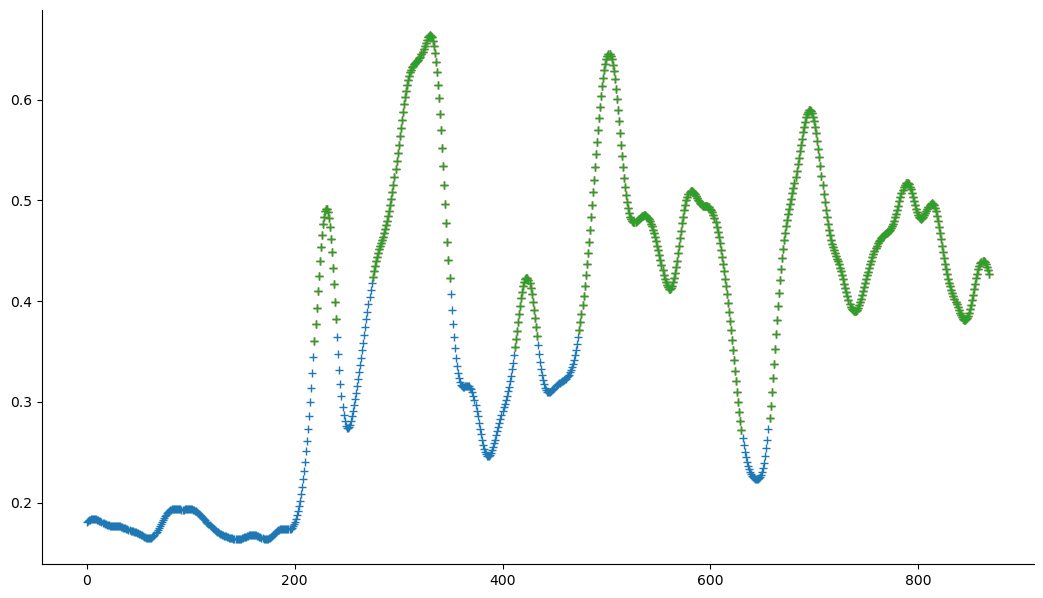

In [5]:
e = raw_stack[0,0,0]
plt.plot(e)
i = analysis.remove_nan_rows(index_stack[0,0].reshape(-1,1))
f = analysis.remove_nan_rows(filtered_stack[0,0,0].reshape(-1,1))
plt.plot(i,f)
plt.plot(i[:,0],raw_stack[0,0,0,i[:,0].astype(int)])

## save each subject's raw trial emg stack

In [6]:
# if not Path("raw_stacks").exists():
#     Path.mkdir("raw_stacks")

# for subject_idx, subject in enumerate(subjects):
#     raw_stack = load_raw_trial_stack(subject)
#     # write this to disk for later
#     np.save("raw_stacks/raw_stack_" + str(subject_idx) + ".npy",raw_stack)
#     print(subject_idx, raw_stack.shape)

## filter each raw stack and save the indices

In [7]:
# if not Path("filtered_stacks").exists():
#     Path.mkdir("filtered_stacks")

# if not Path("index_stacks").exists():
#     Path.mkdir("index_stacks")

# for subject_idx, subject in enumerate(subjects):
#     print("Subject ", subject_idx)
#     raw_stack = load_raw_stack_from_disk(subject_idx)
#     filtered_stack, index_stack = filter_subject_trial_stack(raw_stack)
#     print(filtered_stack.shape, index_stack.shape)
#     np.save("filtered_stacks/filtered_stack_" + str(subject_idx) + ".npy",filtered_stack)
#     np.save("index_stacks/index_stack_" + str(subject_idx) + ".npy",index_stack)

In [101]:
good_session_idx = 44
good_target_idx = 6

long_session_idx = 2
long_target_idx = 0

## inspect EMG, filtered, indices

In [40]:
subject_idx = 1
raw_stack = load_raw_stack_from_disk(subject_idx)
filtered_stack = load_filtered_stack_from_disk(subject_idx)
index_stack = load_index_stack_from_disk(subject_idx)

In [41]:
index_stack.shape

(45, 12, 2000)

(2000, 64)
(64, 2000)
(503, 1)


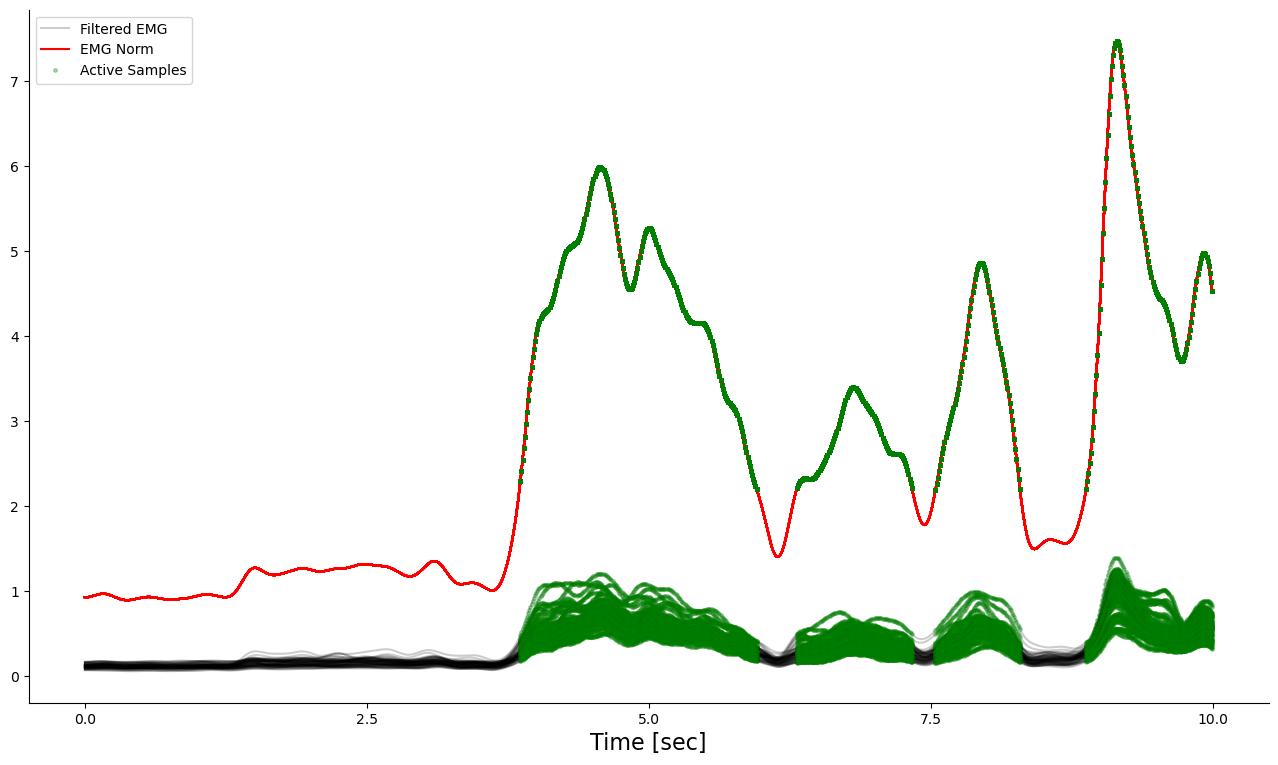

In [111]:
e = raw_stack[long_session_idx,long_target_idx].T
print(e.shape)
f = filtered_stack[long_session_idx,long_target_idx]
print(f.shape)
indices = analysis.remove_nan_rows(index_stack[long_session_idx,long_target_idx].reshape(-1,1)).astype(int)
print(indices.shape)

fig = plt.figure(figsize=(16,9))
handles = []
for ch in range(0,64):
    if ch not in [56]:
        h1, = plt.plot(e[:,ch],'k-',alpha=0.2,label="Filtered EMG")
        h2, = plt.plot(np.linalg.norm(e,axis=1),"r-",label="EMG Norm")
        h3, = plt.plot(indices, e[indices,ch],'g.',alpha=0.3,markersize=5,label="Active Samples")
        h4, = plt.plot(indices,np.linalg.norm(e,axis=1)[indices],"g.",alpha=1,markersize=5)
plt.xlabel("Time [sec]")
n_samples = e[~np.isnan(e[:,0])].shape[0]
ticks = np.linspace(0,n_samples,5,endpoint=True)
labels = np.round(ticks / 100, 1)
plt.gca().set_xticks(ticks)
plt.gca().set_xticklabels([l for l in labels])
plt.legend(handles=[h1,h2,h3],loc=2)

In [112]:
plot.save_figure(fig, "activity_filter_long_trial", image_path)

Figure saved to /Users/spencer/phd/phd/images/methods/activity_filter_long_trial.pdf


(2000, 64)
(64, 2000)
(105, 1)


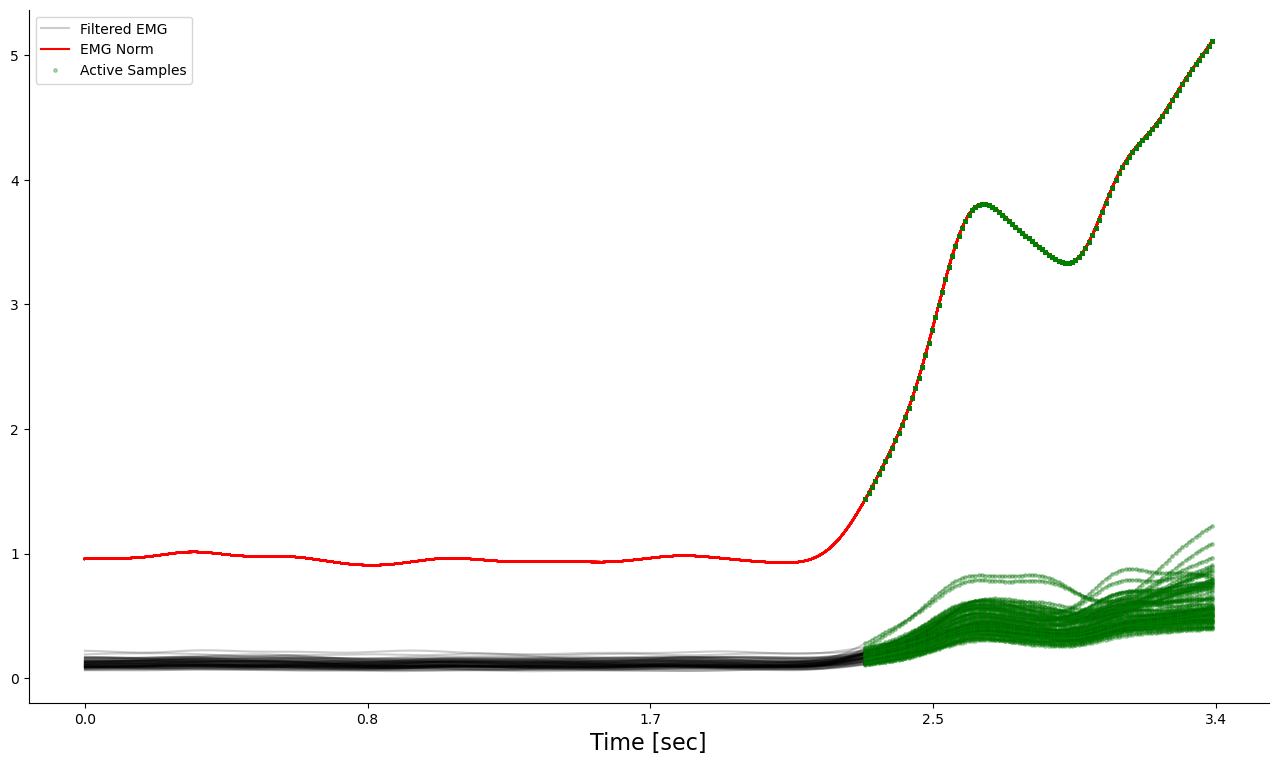

In [109]:
e = raw_stack[good_session_idx,good_target_idx].T
print(e.shape)
f = filtered_stack[good_session_idx,good_target_idx]
print(f.shape)
indices = analysis.remove_nan_rows(index_stack[good_session_idx,good_target_idx].reshape(-1,1)).astype(int)
print(indices.shape)

fig = plt.figure(figsize=(16,9))
handles = []
for ch in range(0,64):
    if ch not in [56]:
        h1, = plt.plot(e[:,ch],'k-',alpha=0.2,label="Filtered EMG")
        h2, = plt.plot(np.linalg.norm(e,axis=1),"r-",label="EMG Norm")
        h3, = plt.plot(indices, e[indices,ch],'g.',alpha=0.3,markersize=5,label="Active Samples")
        h4, = plt.plot(indices,np.linalg.norm(e,axis=1)[indices],"g.",alpha=1,markersize=5)
plt.xlabel("Time [sec]")
n_samples = e[~np.isnan(e[:,0])].shape[0]
ticks = np.linspace(0,n_samples,5,endpoint=True)
labels = np.round(ticks / 100, 1)
plt.gca().set_xticks(ticks)
plt.gca().set_xticklabels([l for l in labels])
plt.legend(handles=[h1,h2,h3],loc=2)

In [110]:
plot.save_figure(fig, "activity_filter_good_trial", image_path)

Figure saved to /Users/spencer/phd/phd/images/methods/activity_filter_good_trial.pdf


## save raw and filtered trajectories

In [23]:
# raw_trajectory_stacks = np.zeros(shape=(46,45,12,2,2000))
# raw_trajectory_stacks[:] = np.nan
# filtered_trajectory_stacks = np.zeros_like(raw_trajectory_stacks)
# filtered_trajectory_stacks[:] = np.nan

# for subject_idx, subject in enumerate(subjects):
#     print("Subject ", subject_idx)
#     raw_trajectory_stack = load_raw_trajectory_stack(subject)
#     raw_trajectory_stacks[subject_idx] = raw_trajectory_stack
#     index_stack = load_index_stack_from_disk(subject_idx)
#     for session_idx, session in enumerate(raw_trajectory_stack):
#         for target_idx, trial in enumerate(session):
#             indices = analysis.remove_nan_rows(index_stack[session_idx,target_idx].reshape(-1,1))
#             filtered_trajectory = trial[:,indices.reshape(-1).astype(int)]
#             filtered_trajectory_stacks[subject_idx,session_idx,target_idx,:,:indices.shape[0]] = filtered_trajectory
# print(raw_trajectory_stacks.shape)

In [24]:
# np.save("subject_raw_trajectory_stacks.npy", raw_trajectory_stacks)
# del raw_trajectory_stacks

# np.save("subject_filtered_trajectory_stacks.npy", filtered_trajectory_stacks)
# del filtered_trajectory_stacks

## inspect trajectory

In [44]:
subject_raw_trajectory_stacks = np.load("../subject_raw_trajectory_stacks.npy")
print(subject_raw_trajectory_stacks.shape)

subject_filtered_trajectory_stacks = np.load("../subject_filtered_trajectory_stacks.npy")
print(subject_filtered_trajectory_stacks.shape)

(46, 45, 12, 2, 2000)
(46, 45, 12, 2, 2000)


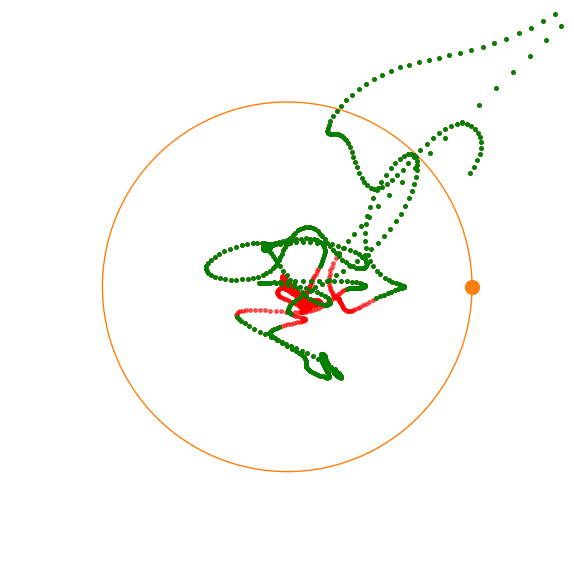

In [103]:
target_vec = collection.compute_target_vec_from_number(long_target_idx+1)
fig = plt.figure()
# for long_session_idx in range(45):
t = subject_raw_trajectory_stacks[subject_idx,long_session_idx,long_target_idx]
plt.plot(t[0],t[1],"r.",alpha=0.6,markersize=5)
l = 2
plt.plot([-l,-l,l,l,-l],[-l,l,l,-l,-l],'k')
c = plt.Circle([0,0],1,color="tab:orange",linestyle="-",fill=None)
plt.gca().add_patch(c)

# for long_session_idx in range(45):
tf = subject_filtered_trajectory_stacks[subject_idx,long_session_idx,long_target_idx]
plt.plot(tf[0],tf[1],"g.",alpha=1.,markersize=5,label="Active Samples")

plt.plot(target_vec[0],target_vec[1],"tab:orange",marker="o",markersize=10,label="Target")
plt.ylim([-1.5,1.5])
plt.xlim([-1.5,1.5])
plt.xticks([])
plt.yticks([])
plt.gca().set_frame_on(False)
plt.gca().set_aspect("equal")

In [104]:
plot.save_figure(fig, "trajectory_filter_long_trial",image_path)

Figure saved to /Users/spencer/phd/phd/images/methods/trajectory_filter_long_trial.pdf


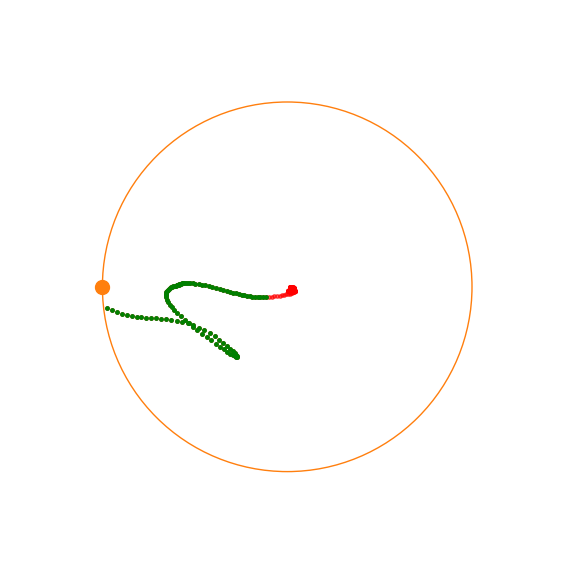

In [105]:
target_vec = collection.compute_target_vec_from_number(good_target_idx+1)
fig = plt.figure()
# for session_idx in range(45):
t = subject_raw_trajectory_stacks[subject_idx,good_session_idx,good_target_idx]
plt.plot(t[0],t[1],"r.",alpha=0.6,markersize=5)
l = 2
plt.plot([-l,-l,l,l,-l],[-l,l,l,-l,-l],'k')
c = plt.Circle([0,0],1,color="tab:orange",linestyle="-",fill=None)
plt.gca().add_patch(c)

# for session_idx in range(45):
tf = subject_filtered_trajectory_stacks[subject_idx,good_session_idx,good_target_idx]
plt.plot(tf[0],tf[1],"g.",alpha=1.,markersize=5,label="Active Samples")

plt.plot(target_vec[0],target_vec[1],"tab:orange",marker="o",markersize=10,label="Target")
plt.ylim([-1.5,1.5])
plt.xlim([-1.5,1.5])
plt.xticks([])
plt.yticks([])
plt.gca().set_frame_on(False)
plt.gca().set_aspect("equal")

In [106]:
plot.save_figure(fig, "trajectory_filter_good_trial",image_path)

Figure saved to /Users/spencer/phd/phd/images/methods/trajectory_filter_good_trial.pdf


## inspect histograms

Text(0.5, 36.72222222222221, 'Log of EMG Norm')

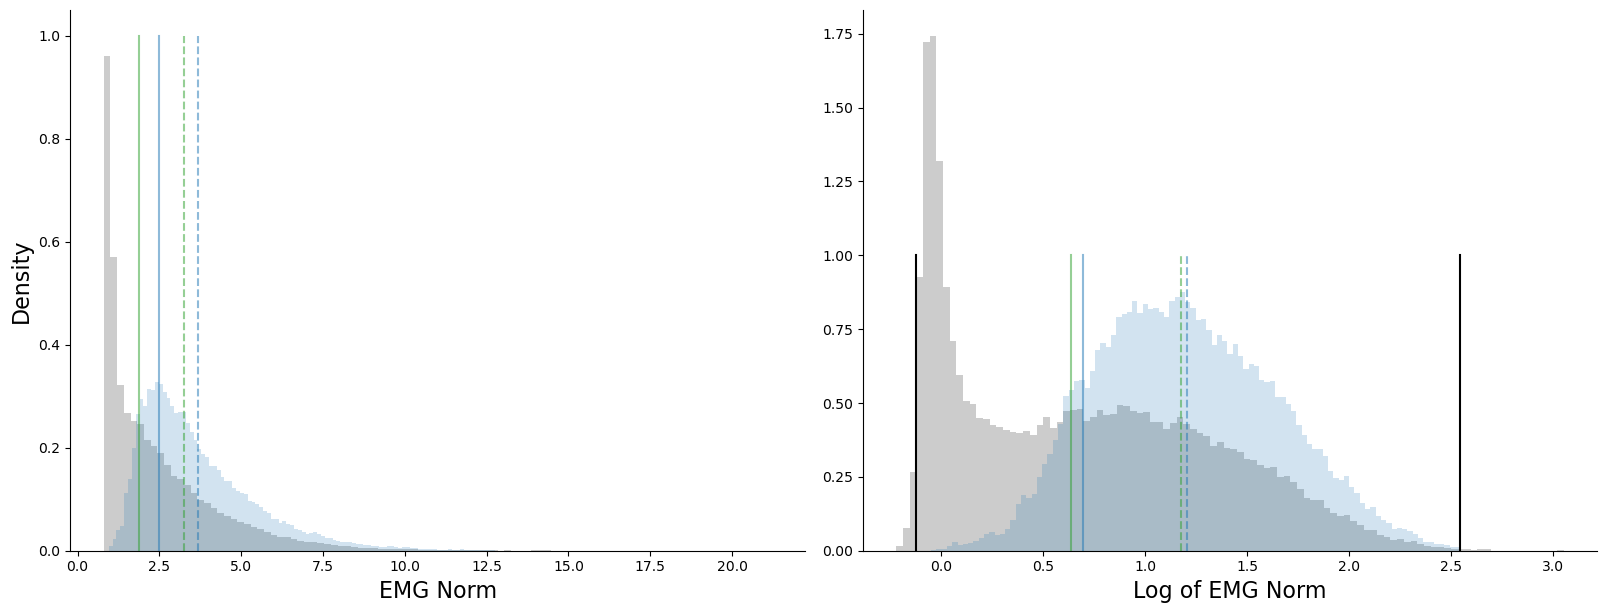

In [10]:
def plot_stats(signal, ax, linestyle="-", label="", **kwargs):
    mean = np.mean(signal)
    ax.plot([mean, mean], [0,1],'tab:blue',linestyle=linestyle,label="Mean " + label,alpha=0.5, marker="",**kwargs)
    median = np.median(signal)
    ax.plot([median, median], [0,1],'tab:green',linestyle=linestyle,label="Median " + label,alpha=0.5, marker="",**kwargs)

subject_idx = 1

raw_stack = load_raw_stack_from_disk(subject_idx)
filtered_stack = load_filtered_stack_from_disk(subject_idx)

raw_samples = analysis.remove_nan_rows(raw_stack.transpose(0,1,3,2).reshape(-1,64))
filtered_samples = analysis.remove_nan_rows(filtered_stack.transpose(0,1,3,2).reshape(-1,64))

fig, axes = plt.subplots(1,2,figsize=(16,6))
fig.tight_layout()

raw_norms = np.linalg.norm(raw_samples,axis=1)
filtered_norms = np.linalg.norm(filtered_samples,axis=1)
raw_log_norms = np.log(np.linalg.norm(raw_samples,axis=1))
filtered_log_norms = np.log(np.linalg.norm(filtered_samples,axis=1))

# sample norms
axes[0].hist(raw_norms,color="k",density=True,alpha=0.2,bins=100,label="Raw Norms")
plot_stats(raw_norms, axes[0],label=" Raw")
# filtered norms
axes[0].hist(filtered_norms,color="tab:blue",density=True,alpha=0.2,bins=100,label="Filtered Norms")
plot_stats(filtered_norms,axes[0],linestyle="--",label=" Filtered")
# axes[0].legend()
axes[0].set_xlabel("EMG Norm")
axes[0].set_ylabel("Density")

# sample norms
axes[1].hist(raw_log_norms,color="k",density=True,alpha=0.2,bins=100,label="Raw Norms")
plot_stats(raw_log_norms, axes[1],label=" Raw")
# filtered norms
axes[1].hist(filtered_log_norms,color="tab:blue",density=True,alpha=0.2,bins=100,label="Filtered Norms")
plot_stats(filtered_log_norms,axes[1],linestyle="--",label=" Filtered")

cutoffs = compute_cutoffs(raw_stack)
axes[1].plot([cutoffs[0],cutoffs[0]],[0,1],"k-")
axes[1].plot([cutoffs[1],cutoffs[1]],[0,1],"k-")
axes[1].set_xlabel("Log of EMG Norm")
# axes[1].set_ylabel("Density")
# axes[1].legend()


In [11]:
plot.save_figure(fig, f"log_hist_trial", image_path)

Figure saved to /Users/spencer/phd/phd/images/methods/log_hist_trial.pdf
